# Curación de imágenes: máscara de color de la galaxia central

Limpieza de **contaminación por estrellas** en los cutouts `.jpg` de legacysurvey.org (Fase 2, ver
`README.md`, sección "Limpieza de imágenes"). Objetivo: que en cada imagen solo quede la galaxia
del centro; las estrellas lejos de ella se eliminan, las que caen encima del disco se conservan.

**Idea:** los cutouts vienen centrados en la galaxia objetivo, así que su tono se estima con los
píxeles del centro y el del cielo con el marco de la imagen. Como el estiramiento del visor cambia
los tonos de imagen a imagen, ambos modelos de color se ajustan **por imagen**. La lógica vive en
`src/data/galaxy_mask.py` y los parámetros en `src/config.py` (`GALAXY_MASK_*`); este notebook
solo la explora y la valida visualmente.

Imagen de referencia: `manga-8589-12705.jpg`.

**Variante.** Los cutouts están organizados por capa y bandas del visor:
`data/legacy_cutouts/jpg/<layer>_<bands>/` y, los enmascarados, `jpg_masked/<layer>_<bands>/`
(ver `README.md`, sección "Variantes de capa y bandas"). Las secciones 1–4 trabajan sobre la
variante elegida en `LAYER`/`BANDS` (por defecto la activa en `src/config.py`); la sección 5
compara todas las variantes.

**Resultado clave (sección 7):** la máscara y los demás tratamientos de imagen probados no mejoran
al clasificador temprana/tardía. Ninguno supera a la imagen original y la mayoría la empeora de
forma significativa. La máscara sirve para **medir** (tamaño, forma y color de la galaxia), no
como entrada del modelo.

In [1]:
# importaciones de sistema
import sys
from pathlib import Path

# Referencia a otros archivos sin necesidad de instalar el paquete
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# importaciones de librerias de terceros
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle
from scipy import ndimage as ndi

In [2]:
# configuracion de proyecto
from src.config import (
    CUTOUT_FORMAT_JPG,
    CUTOUTS_INDEX_CSV,
    CUTOUTS_MASKED_JPG_DIR,
    GALAXY_MASK_BG_PERCENTILE,
    GALAXY_MASK_BORDER_PX,
    GALAXY_MASK_CENTER_FRAC,
    GALAXY_MASK_COV_REG,
    GALAXY_MASK_SMOOTH_SIGMA,
    LEGACY_BANDS,
    LEGACY_LAYER,
    LEGACY_VARIANTS,
)
from src.data.cutout_io import load_jpg_cutout
from src.data.download_cutouts import summarize_variants
from src.data.legacy_cutouts import list_cutout_names, variant_dir, variant_name
from src.data.galaxy_mask import (
    _color_model,
    _mahalanobis_sq,
    apply_mask,
    galaxy_color_mask,
    save_masked_cutout,
)

# Variante sobre la que se trabaja en las secciones 1-4 (cambiar para explorar otra,
# p. ej. LAYER, BANDS = "ls-dr11", "grz").
LAYER, BANDS = LEGACY_LAYER, LEGACY_BANDS
VARIANT = variant_name(LAYER, BANDS)

REFERENCE_NAME = "manga-8589-12705"
names = list_cutout_names(CUTOUT_FORMAT_JPG, LAYER, BANDS)
print(f"{len(names)} cutouts en {variant_dir(CUTOUT_FORMAT_JPG, LAYER, BANDS)}")

50 cutouts en C:\Users\Alexander CC\Documents\Projects\python\clasificacion-galaxias\data\legacy_cutouts\jpg\ls-dr10_grz


## 1. Imagen de referencia: regiones de muestreo de color

- **Círculo amarillo**: disco central de radio `GALAXY_MASK_CENTER_FRAC` × lado → tono de la galaxia.
  Con 0.12 abarca bulbo y disco interno; un radio menor solo ve el núcleo (casi saturado,
  amarillento) y el disco azulado de las espirales queda fuera del modelo.
- **Marco cian**: `GALAXY_MASK_BORDER_PX` px de borde → color del cielo (sin su 5% más brillante,
  `GALAXY_MASK_BG_PERCENTILE`, para no contar las estrellas que caen en el borde).

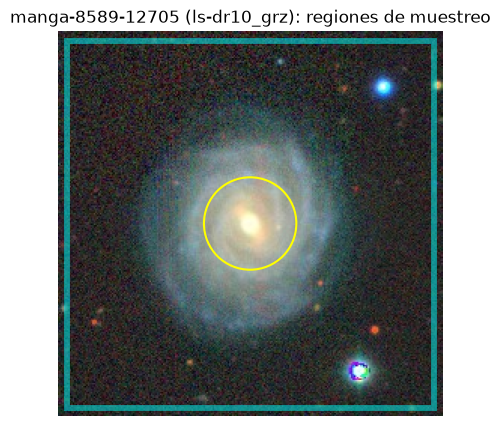

In [3]:
ref = load_jpg_cutout(REFERENCE_NAME, LAYER, BANDS)
h, w, _ = ref.shape
b = GALAXY_MASK_BORDER_PX

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(ref)
ax.add_patch(Circle(((w - 1) / 2, (h - 1) / 2), GALAXY_MASK_CENTER_FRAC * min(h, w),
                    fill=False, color="yellow", lw=1.5))
ax.add_patch(Rectangle((b / 2, b / 2), w - b, h - b, fill=False, color="cyan", lw=b * 0.35, alpha=0.5))
ax.set_title(f"{REFERENCE_NAME} ({VARIANT}): regiones de muestreo")
ax.axis("off")
plt.show()

### Colores de galaxia vs. cielo

Distribución RGB (tras el suavizado) de cada región. El núcleo es blanco-amarillento y el disco
azulado, mientras el cielo es oscuro y rojizo: la separación es en **color + brillo**, no solo en
tono. Las estrellas azules tienen un color parecido al disco, por eso el color no basta para
eliminarlas y el paso de **conectividad** (quedarse con la región pegada al centro) es el que las
quita.

,R,G,B
galaxia (centro),180.2,180.2,163.6
cielo (marco),40.9,37.9,36.9


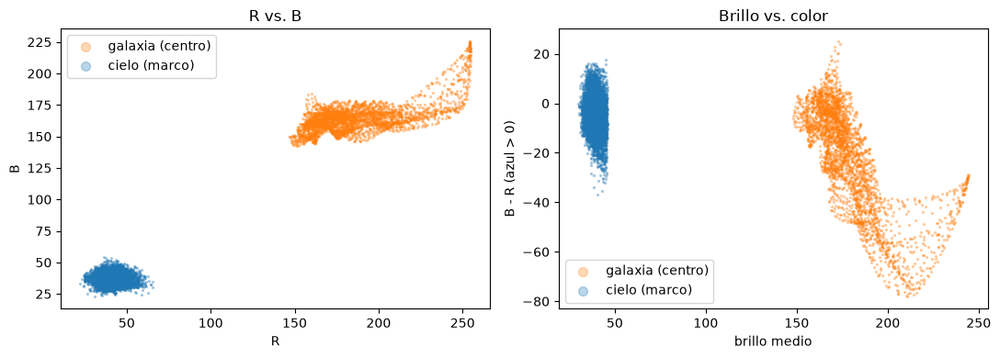

In [4]:
smoothed = ndi.gaussian_filter(ref.astype(float), sigma=(GALAXY_MASK_SMOOTH_SIGMA, GALAXY_MASK_SMOOTH_SIGMA, 0))
yy, xx = np.mgrid[:h, :w]
radius = np.hypot(yy - (h - 1) / 2, xx - (w - 1) / 2)
border = np.zeros((h, w), bool)
border[:b] = border[-b:] = True
border[:, :b] = border[:, -b:] = True

sky = smoothed[border]
sky = sky[sky.mean(1) < np.percentile(sky.mean(1), GALAXY_MASK_BG_PERCENTILE)]
regions = {
    "galaxia (centro)": smoothed[radius <= GALAXY_MASK_CENTER_FRAC * min(h, w)],
    "cielo (marco)": sky,
}
display(pd.DataFrame(
    {k: np.median(v, axis=0).round(1) for k, v in regions.items()}, index=["R", "G", "B"]
).T)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for (label, px), color in zip(regions.items(), ["tab:orange", "tab:blue"]):
    axes[0].scatter(px[:, 0], px[:, 2], s=2, alpha=0.3, label=label, color=color)
    axes[1].scatter(px.mean(1), px[:, 2] - px[:, 0], s=2, alpha=0.3, label=label, color=color)
axes[0].set(xlabel="R", ylabel="B", title="R vs. B")
axes[1].set(xlabel="brillo medio", ylabel="B - R (azul > 0)", title="Brillo vs. color")
for ax in axes:
    ax.legend(markerscale=5)
plt.tight_layout()
plt.show()

## 2. Paso a paso sobre la referencia

1. Candidatos: píxeles cuyo color está más cerca (distancia de Mahalanobis) del modelo de la
   galaxia que del modelo del cielo. Aquí aparecen también las estrellas.
2. Máscara final: apertura morfológica (corta puentes finos), componente conexa que contiene el
   centro, cierre, relleno de huecos y un margen de `GALAXY_MASK_MARGIN_PX` px alrededor para que
   la galaxia no quede "encerrada" en su contorno (`src/data/galaxy_mask.py`).

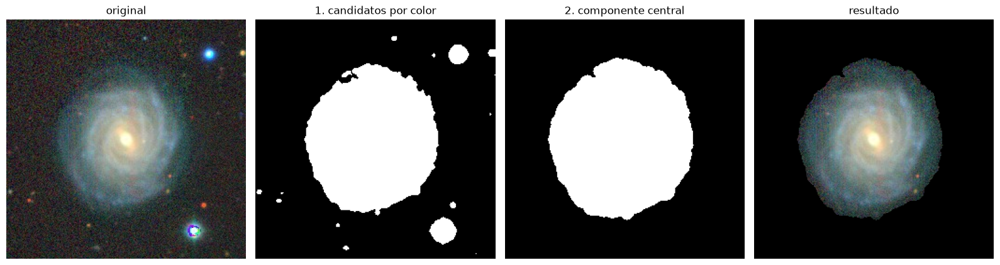

Fracción de la imagen cubierta por la galaxia: 30.8%


In [5]:
candidates = (
    _mahalanobis_sq(smoothed, _color_model(regions["galaxia (centro)"], GALAXY_MASK_COV_REG))
    < _mahalanobis_sq(smoothed, _color_model(regions["cielo (marco)"], GALAXY_MASK_COV_REG))
)
mask = galaxy_color_mask(ref)

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
panels = [(ref, "original"), (candidates, "1. candidatos por color"),
          (mask, "2. componente central"), (apply_mask(ref, mask), "resultado")]
for ax, (img, title) in zip(axes, panels):
    ax.imshow(img, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()
print(f"Fracción de la imagen cubierta por la galaxia: {mask.mean():.1%}")

## 3. Validación visual sobre toda la muestra

Original / enmascarada, lado a lado (encima de la enmascarada, % de la imagen que cubre la
máscara). Revisar sobre todo: (a) estrellas lejanas eliminadas, (b) disco externo débil
conservado, (c) galaxias vecinas.

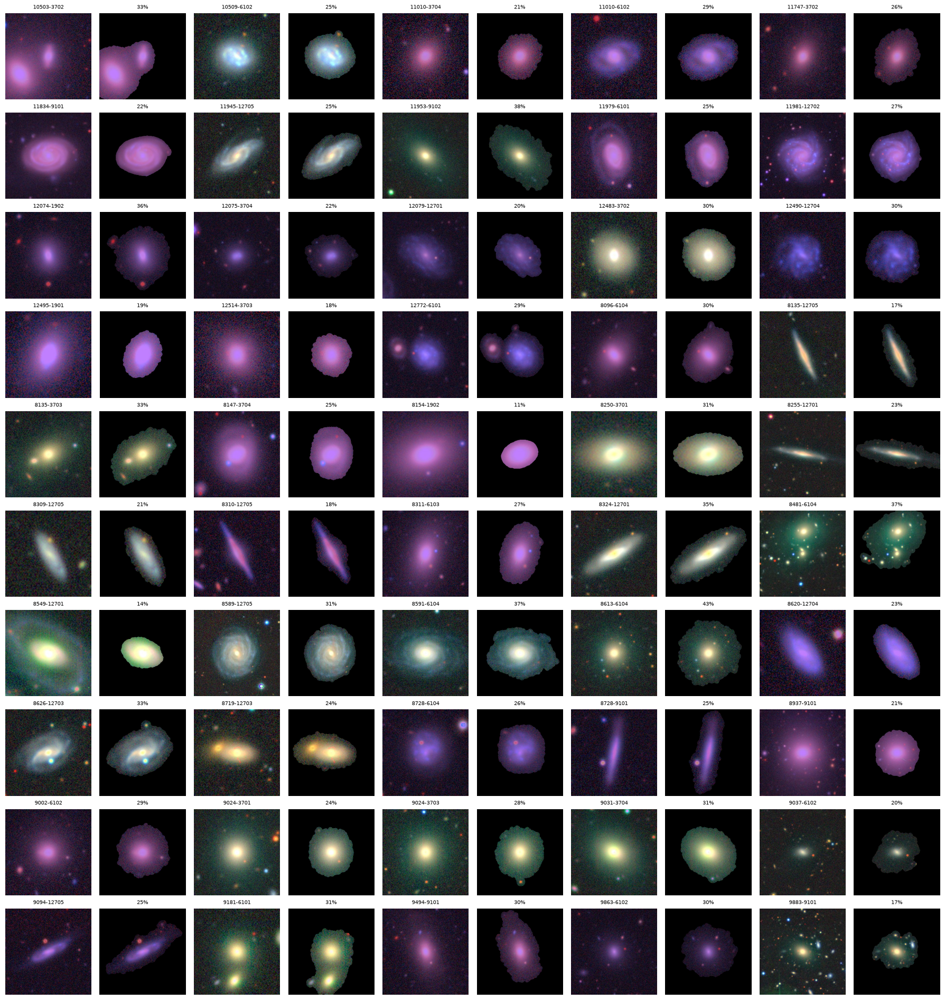

In [6]:
coverage = {}
n_cols = 5
n_rows = int(np.ceil(len(names) / n_cols))
fig, axes = plt.subplots(n_rows, 2 * n_cols, figsize=(2 * n_cols * 1.8, n_rows * 1.9))
for ax in axes.ravel():
    ax.axis("off")
for i, name in enumerate(names):
    image = load_jpg_cutout(name, LAYER, BANDS)
    m = galaxy_color_mask(image)
    coverage[name] = m.mean()
    r, c = divmod(i, n_cols)
    axes[r, 2 * c].imshow(image)
    axes[r, 2 * c].set_title(name.replace("manga-", ""), fontsize=7)
    axes[r, 2 * c + 1].imshow(apply_mask(image, m))
    axes[r, 2 * c + 1].set_title(f"{m.mean():.0%}", fontsize=7)
plt.tight_layout()
plt.show()

In [7]:
coverage = pd.Series(coverage, name="fraccion_mascara").sort_values()
display(coverage.describe().to_frame().T)
print("Menor cobertura (posible máscara recortada de más):")
display(coverage.head(5).to_frame())
print("Mayor cobertura (posible fusión con vecinas o halo de fondo):")
display(coverage.tail(5).to_frame())

,count,mean,std,min,25%,50%,75%,max
fraccion_mascara,50.0,0.264712,0.065866,0.111023,0.219788,0.26268,0.304943,0.428116


Menor cobertura (posible máscara recortada de más):


,fraccion_mascara
manga-8154-1902,0.111023
manga-8549-12701,0.135742
manga-8135-12705,0.166901
manga-9883-9101,0.172562
manga-8310-12705,0.179626


Mayor cobertura (posible fusión con vecinas o halo de fondo):


,fraccion_mascara
manga-12074-1902,0.364044
manga-8591-6104,0.367889
manga-8481-6104,0.374725
manga-11953-9102,0.375610
manga-8613-6104,0.428116


### Observaciones

- Las estrellas separadas de la galaxia se eliminan en prácticamente toda la muestra, incluida la
  estrella azul brillante de la imagen de referencia.
- Las estrellas superpuestas al disco se conservan (no se pueden separar por conectividad), como
  se acordó.
- **Limitación:** si una galaxia vecina se superpone a la central (pares en interacción, grupos),
  queda dentro de la misma máscara. Separarlas requeriría deblending (p. ej. watershed sobre el
  brillo o `photutils.segmentation.deblend_sources`), fuera del alcance de esta máscara de color.
- **Limitación:** en algunas espirales con bulbo muy dominante, el disco externo débil tiene un
  color más cercano al cielo que al centro y queda fuera de la máscara.

## 4. Guardar los cutouts enmascarados

Escribe cada imagen de la variante elegida con el fondo en negro en
`CUTOUTS_MASKED_JPG_DIR/<layer>_<bands>/` (`data/legacy_cutouts/jpg_masked/`, no versionado).
Para enmascarar todas las variantes de una vez (y registrar las estadísticas en el índice):
`python -m src.data.download_cutouts --variants all`.

In [8]:
saved = pd.DataFrame.from_dict(
    {name: save_masked_cutout(name, LAYER, BANDS) for name in names}, orient="index"
)
empty = saved.index[saved["mask_frac"] == 0].tolist()
print(f"{len(saved)} imágenes guardadas en {CUTOUTS_MASKED_JPG_DIR / VARIANT}; máscaras vacías: {empty}")
print(f"Máscaras que tocan el borde: {saved['mask_toca_borde'].sum()}")

50 imágenes guardadas en C:\Users\Alexander CC\Documents\Projects\python\clasificacion-galaxias\data\legacy_cutouts\jpg_masked\ls-dr10_grz; máscaras vacías: []
Máscaras que tocan el borde: 4


## 5. Comparación entre variantes de capa y bandas

Misma galaxia y misma máscara, cambiando solo el render del visor. Requiere haber descargado las
variantes (`python -m src.data.download_cutouts --variants all`); las que falten en disco se
omiten. Qué mirar (ver `README.md`, sección "Variantes de capa y bandas"): (a) tono de color
homogéneo entre galaxias — `ls-dr10_grz` tiñe de morado las del sur (`objdec < 32.4°`); (b) cuánto
disco externo conserva la máscara — con `griz`/`gri` el núcleo sale más estirado y la máscara
recorta los brazos.

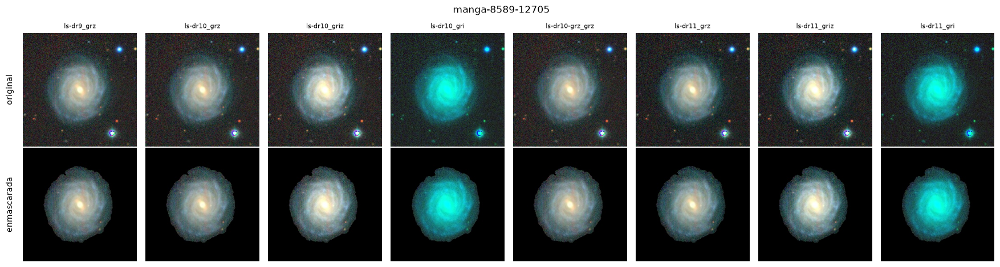

In [9]:
available = [(l, b) for l, b in LEGACY_VARIANTS if REFERENCE_NAME in list_cutout_names(CUTOUT_FORMAT_JPG, l, b)]

fig, axes = plt.subplots(2, len(available), figsize=(2.2 * len(available), 4.8), squeeze=False)
for col, (layer, bands) in enumerate(available):
    axes[0, col].imshow(load_jpg_cutout(REFERENCE_NAME, layer, bands))
    axes[0, col].set_title(variant_name(layer, bands), fontsize=8)
    axes[1, col].imshow(load_jpg_cutout(REFERENCE_NAME, layer, bands, masked=True))
for ax in axes.ravel():
    ax.axis("off")
axes[0, 0].text(-0.08, 0.5, "original", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right")
axes[1, 0].text(-0.08, 0.5, "enmascarada", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right")
plt.suptitle(REFERENCE_NAME)
plt.tight_layout()
plt.show()

In [10]:
# Resumen por variante a partir del índice de descargas (una fila por galaxia y variante).
index = pd.read_csv(CUTOUTS_INDEX_CSV)
jpg_index = index[index["format"] == CUTOUT_FORMAT_JPG]
display(summarize_variants(jpg_index))

# Fracción media cubierta por la máscara, por clase: una diferencia grande entre clases
# significa que el contorno de la máscara por sí solo ya delata la etiqueta.
display(jpg_index.pivot_table(index="variante", columns="label", values="mask_frac").round(3))

ok  errores     mb  con_zona_sin_cobertura  \
format variante                                                      
jpg    ls-dr9_grz       50        0  1.183                       0   
       ls-dr10_grz      50        0  1.110                       0   
       ls-dr10_griz     50        0  1.218                       0   
       ls-dr10_gri      50        0  0.984                       0   
       ls-dr10-grz_grz  50        0  1.162                       0   
       ls-dr11_grz      50        0  1.169                       0   
       ls-dr11_griz     50        0  1.203                       0   
       ls-dr11_gri      50        0  0.986                       0   

                        mascara_vacia  mascara_toca_borde  mask_frac_media  
format variante                                                             
jpg    ls-dr9_grz                   0                   4            0.281  
       ls-dr10_grz                  0                   4            0.265  
       ls-dr10_griz                 0                   4            0.240  
       ls-dr10_gri                  0                   4            0.242  
       ls-dr10-grz_grz              0                   4            0.283  
       ls-dr11_grz                  0                   5            0.282  
       ls-dr11_griz                 0                   5            0.249  
       ls-dr11_gri                  0                   4            0.258

label,tardia,temprana
variante,,
ls-dr10-grz_grz,0.259,0.306
ls-dr10_gri,0.237,0.248
ls-dr10_griz,0.228,0.251
ls-dr10_grz,0.248,0.282
ls-dr11_gri,0.251,0.265
ls-dr11_griz,0.238,0.261
ls-dr11_grz,0.258,0.305
ls-dr9_grz,0.257,0.304


## 6. Filtro 1: calidad y atajos por variante

Antes de comparar variantes entrenando un clasificador (eso está en
`notebook/variant-classification-for-images-only.ipynb`), se descartan las que tienen problemas objetivos. Ver
`README.md`, sección "Elegir la variante de imágenes".

1. **Calidad:** cobertura incompleta, máscaras vacías o que tocan el borde.
2. **Homogeneidad de color:** Legacy Surveys combina dos telescopios según la posición en el cielo:
   *norte* (BASS/MzLS, `dec >= 32.375°` en el casquete galáctico norte) y *sur* (DECam). Una buena
   variante pinta igual las dos regiones.
3. **Fuga norte/sur:** ¿se puede adivinar la región a partir de la imagen? Solo es un **atajo
   peligroso** si además la región está asociada a la clase (temprana/tardía); si no, el modelo no
   gana nada aprendiéndola, pero sí puede generalizar peor de una región a otra.

La lógica vive en `src/data/image_quality.py` (features), `src/evaluate.py`
(`predictability_test`: AUC con validación cruzada repetida + p-valor por permutación) y
`src/models/linear_probe.py` (features de una ResNet-34 de ImageNet congelada).

> **Muestra chica:** 50 galaxias (23 norte / 27 sur). Sirve para detectar efectos grandes, como el
> render morado de `ls-dr10_grz`; diferencias finas entre variantes necesitan la muestra ampliada
> (`python -m src.data.download_cutouts --variants all --n 2000`) y volver a correr la sección.

In [11]:
import warnings

from src.config import (
    LEGACY_REGION_NORTH,
    LEGACY_REGION_SOUTH,
    MORFOLOGIA_CURATED_CSV,
    SHORTCUT_AUC_ALERT,
    SHORTCUT_LOGREG_C,
    SHORTCUT_P_VALUE_MAX,
)
from src.data.image_quality import (
    COLOR_FEATURES,
    build_variant_feature_table,
    legacy_region,
    quality_flags,
    region_color_gap,
)
from src.evaluate import predictability_test
from src.models.linear_probe import build_backbone, embed_cutouts, make_logistic_probe
from src.utils import set_seed

set_seed()
warnings.filterwarnings("ignore", category=UserWarning)  # avisos de sklearn/torch en paralelo

# Colores fijos por entidad (paleta categórica validada, slots 1 y 2).
REGION_COLORS = {LEGACY_REGION_NORTH: "#2a78d6", LEGACY_REGION_SOUTH: "#eb6834"}

features = build_variant_feature_table(pd.read_csv(CUTOUTS_INDEX_CSV))
variants = list(features["variante"].cat.categories)
print(f"{features['name'].nunique()} galaxias x {len(variants)} variantes")
display(features.drop_duplicates("name")["region"].value_counts().to_frame())

50 galaxias x 8 variantes


,count
region,
sur,27
norte,23


### 6.1 Calidad

Conteo de galaxias con cada problema, por variante. `mascara_toca_borde` casi siempre es la misma
galaxia en todas las variantes (galaxia más grande que el encuadre): se resuelve ampliando
`CUTOUT_FOV_FACTOR`, no cambiando de variante.

In [12]:
display(quality_flags(features))

flagged = features[features["mask_toca_borde"].astype(bool)]
print("Galaxias cuya máscara toca el borde (para la revisión manual):")
display(pd.crosstab(flagged["name"], flagged["variante"]).astype(bool).replace({True: "x", False: ""}))

,n,con_zona_sin_cobertura,mascara_vacia,mascara_toca_borde
variante,,,,
ls-dr9_grz,50,0,0,4
ls-dr10_grz,50,0,0,4
ls-dr10_griz,50,0,0,4
ls-dr10_gri,50,0,0,4
ls-dr10-grz_grz,50,0,0,4
ls-dr11_grz,50,0,0,5
ls-dr11_griz,50,0,0,5
ls-dr11_gri,50,0,0,4


Galaxias cuya máscara toca el borde (para la revisión manual):


variante,ls-dr9_grz,ls-dr10_grz,ls-dr10_griz,ls-dr10_gri,ls-dr10-grz_grz,ls-dr11_grz,ls-dr11_griz,ls-dr11_gri
name,,,,,,,,
manga-10503-3702,x,x,x,x,x,x,x,x
manga-8255-12701,x,x,x,x,x,x,x,x
manga-8481-6104,x,x,x,x,x,x,x,x
manga-8728-9101,,,,x,,,x,x
manga-9181-6101,x,x,x,,x,x,x,
manga-9494-9101,,,,,,x,,


### 6.2 Homogeneidad de color entre regiones

Tono del **cielo** (mediana fuera de la máscara) como cromaticidad `r = R/(R+G+B)` y
`g = G/(R+G+B)`, que no depende del brillo. Cada punto es una galaxia. En una variante homogénea las
dos nubes (norte y sur) se superponen; si quedan separadas, el render depende de la región.

La tabla mide la distancia entre la cromaticidad mediana del norte y la del sur (cielo y galaxia).
Todas las variantes tienen algo (son telescopios distintos); se marca `color_heterogeneo` la que
supera `COLOR_GAP_MAX_FACTOR` (2×) la mediana entre variantes.

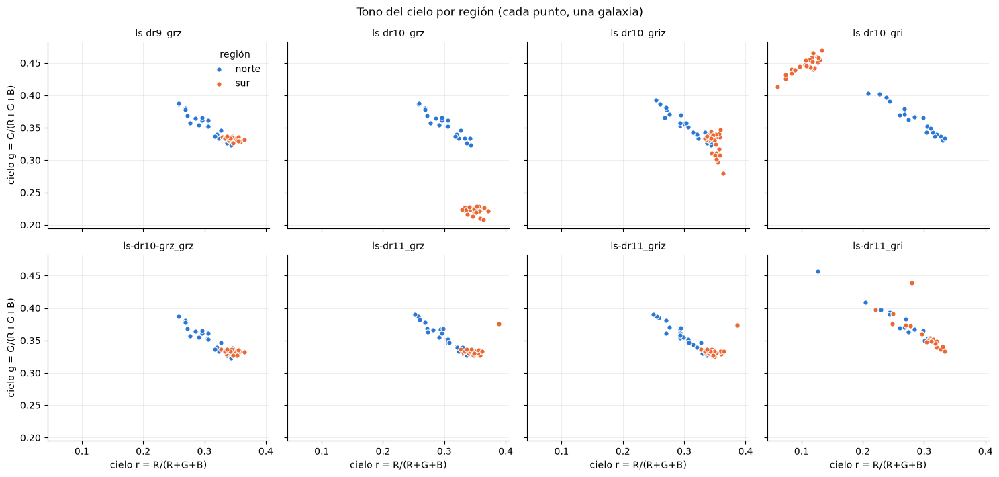

,gap_cielo,gap_galaxia,color_heterogeneo
variante,,,
ls-dr9_grz,0.041,0.061,False
ls-dr10_grz,0.138,0.148,True
ls-dr10_griz,0.051,0.054,False
ls-dr10_gri,0.192,0.013,True
ls-dr10-grz_grz,0.042,0.061,False
ls-dr11_grz,0.042,0.064,False
ls-dr11_griz,0.049,0.061,False
ls-dr11_gri,0.022,0.121,False


In [13]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7.2), sharex=True, sharey=True)
for ax, variant in zip(axes.ravel(), variants):
    subset = features[features["variante"] == variant]
    for region, color in REGION_COLORS.items():
        part = subset[subset["region"] == region]
        ax.scatter(part["cielo_r"], part["cielo_g"], s=28, color=color,
                   edgecolor="white", linewidth=0.8, label=region)
    ax.set_title(variant, fontsize=10)
    ax.grid(alpha=0.25, linewidth=0.6)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel("cielo r = R/(R+G+B)")
for ax in axes[:, 0]:
    ax.set_ylabel("cielo g = G/(R+G+B)")
axes[0, 0].legend(title="región", frameon=False)
fig.suptitle("Tono del cielo por región (cada punto, una galaxia)")
plt.tight_layout()
plt.show()

color_gap = region_color_gap(features).loc[variants]
display(color_gap.round(3))

### 6.3 Fuga norte/sur

**Paso 1 — ¿la región está asociada a la clase?** Si la proporción de tardías fuera muy distinta
entre norte y sur, adivinar la región ayudaría a adivinar la clase (atajo directo). Se mide sobre el
catálogo curado completo, no solo sobre la muestra.

In [14]:
catalog = pd.read_csv(MORFOLOGIA_CURATED_CSV)
catalog["region"] = legacy_region(catalog["objra"], catalog["objdec"])
association = pd.crosstab(catalog["region"], catalog["label"], margins=True)
association["% tardía"] = (100 * association["tardia"] / association["All"]).round(1)
display(association)

label,tardia,temprana,All,% tardía
region,,,,
norte,2754,1674,4428,62.2
sur,3538,2048,5586,63.3
All,6292,3722,10014,62.8


**Paso 2 — ¿se puede adivinar la región desde la imagen?** Para cada variante, AUC (validación
cruzada estratificada 5×10) de una regresión logística que predice *norte* a partir de:

- **color del cielo** y **color de la galaxia** (6 features cada uno, interpretables);
- **ResNet original / enmascarada**: las 512 features de una ResNet-34 de ImageNet congelada, que es
  lo que una CNN "ve". Con la versión enmascarada se comprueba si la máscara elimina la señal.

AUC 0.5 = azar; p-valor por permutación de etiquetas (200 permutaciones; el mínimo posible es
1/201 ≈ 0.005). Tarda unos minutos.

In [15]:
backbone = build_backbone()
sky_cols = [c for c in COLOR_FEATURES if c.startswith("cielo")]
galaxy_cols = [c for c in COLOR_FEATURES if c.startswith("galaxia")]

rows = []
for variant in variants:
    subset = features[features["variante"] == variant].sort_values("name")
    layer, bands = subset[["layer", "bands"]].iloc[0]
    y_region = (subset["region"] == LEGACY_REGION_NORTH).astype(int).to_numpy()
    representations = {
        "color cielo": (subset[sky_cols].to_numpy(), make_logistic_probe(SHORTCUT_LOGREG_C)),
        "color galaxia": (subset[galaxy_cols].to_numpy(), make_logistic_probe(SHORTCUT_LOGREG_C)),
        "ResNet original": (embed_cutouts(subset["name"], layer, bands, backbone), make_logistic_probe()),
        "ResNet enmascarada": (embed_cutouts(subset["name"], layer, bands, backbone, masked=True), make_logistic_probe()),
    }
    for representation, (X, estimator) in representations.items():
        rows.append({"variante": variant, "representacion": representation,
                     **predictability_test(estimator, X, y_region)})

leak = pd.DataFrame(rows)
display(leak.pivot(index="variante", columns="representacion", values="auc_media")
        .loc[variants].round(2))

representacion,ResNet enmascarada,ResNet original,color cielo,color galaxia
variante,,,,
ls-dr9_grz,0.87,0.81,0.94,0.97
ls-dr10_grz,0.99,1.00,1.00,1.00
ls-dr10_griz,0.90,0.94,0.97,0.93
ls-dr10_gri,0.85,1.00,1.00,0.80
ls-dr10-grz_grz,0.86,0.83,0.95,0.97
ls-dr11_grz,0.92,0.81,0.98,0.97
ls-dr11_griz,0.86,0.84,0.99,0.97
ls-dr11_gri,0.82,0.92,0.91,0.95


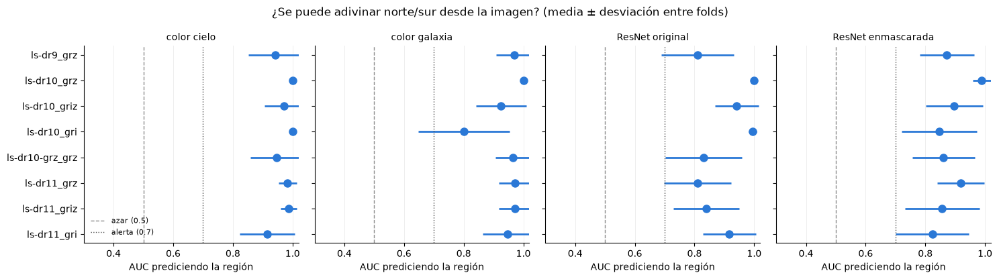

In [16]:
REPR_ORDER = ["color cielo", "color galaxia", "ResNet original", "ResNet enmascarada"]
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2), sharey=True)
ypos = np.arange(len(variants))[::-1]
for ax, representation in zip(axes, REPR_ORDER):
    part = leak[leak["representacion"] == representation].set_index("variante").loc[variants]
    ax.errorbar(part["auc_media"], ypos, xerr=part["auc_std"], fmt="o", markersize=8,
                color="#2a78d6", ecolor="#2a78d6", elinewidth=2, capsize=0)
    ax.axvline(0.5, color="0.55", linewidth=1, linestyle="--", label="azar (0.5)")
    ax.axvline(SHORTCUT_AUC_ALERT, color="0.3", linewidth=1, linestyle=":", label=f"alerta ({SHORTCUT_AUC_ALERT})")
    ax.set_xlim(0.3, 1.02)
    ax.set_title(representation, fontsize=10)
    ax.set_xlabel("AUC prediciendo la región")
    ax.grid(axis="x", alpha=0.25, linewidth=0.6)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_yticks(ypos, variants)
axes[0].legend(loc="lower left", frameon=False, fontsize=8)
fig.suptitle("¿Se puede adivinar norte/sur desde la imagen? (media ± desviación entre folds)")
plt.tight_layout()
plt.show()

### 6.4 Veredicto del filtro 1

Una variante **no pasa** si tiene problemas de calidad propios (cobertura, máscaras vacías) o si su
render de color es heterogéneo entre regiones (`color_heterogeneo`, sección 6.2): dos "dominios" de
color que el modelo tendría que aprender por separado. Que la región se pueda
adivinar con AUC alta **no descalifica por sí solo**: es una diferencia física entre telescopios que
existe en todas las variantes; lo que importa es que no esté asociada a la clase (paso 1) y que el
clasificador rinda igual en ambas regiones, que se mide en `notebook/variant-classification-for-images-only.ipynb`.

In [17]:
flags = quality_flags(features)
auc = leak.pivot(index="variante", columns="representacion", values="auc_media").loc[variants]
verdict = pd.DataFrame({
    "cobertura_incompleta": flags["con_zona_sin_cobertura"],
    "mascaras_vacias": flags["mascara_vacia"],
    "toca_borde": flags["mascara_toca_borde"],
    "gap color cielo": color_gap["gap_cielo"].round(3),
    "gap color galaxia": color_gap["gap_galaxia"].round(3),
    "color_heterogeneo": color_gap["color_heterogeneo"],
    "AUC región (ResNet)": auc["ResNet original"].round(2),
    "AUC región (ResNet masc.)": auc["ResNet enmascarada"].round(2),
}).loc[variants]
verdict["pasa_filtro_1"] = (
    (verdict["cobertura_incompleta"] == 0)
    & (verdict["mascaras_vacias"] == 0)
    & ~verdict["color_heterogeneo"]
)
display(verdict)

,cobertura_incompleta,mascaras_vacias,toca_borde,gap color cielo,gap color galaxia,color_heterogeneo,AUC región (ResNet),AUC región (ResNet masc.),pasa_filtro_1
variante,,,,,,,,,
ls-dr9_grz,0,0,4,0.041,0.061,False,0.81,0.87,True
ls-dr10_grz,0,0,4,0.138,0.148,True,1.00,0.99,False
ls-dr10_griz,0,0,4,0.051,0.054,False,0.94,0.90,True
ls-dr10_gri,0,0,4,0.192,0.013,True,1.00,0.85,False
ls-dr10-grz_grz,0,0,4,0.042,0.061,False,0.83,0.86,True
ls-dr11_grz,0,0,5,0.042,0.064,False,0.81,0.92,True
ls-dr11_griz,0,0,5,0.049,0.061,False,0.84,0.86,True
ls-dr11_gri,0,0,4,0.022,0.121,False,0.92,0.82,True


### Observaciones (muestra de 50, 2026-10-07)

- **Calidad:** ninguna variante tiene huecos de cobertura ni máscaras vacías. Las máscaras que
  tocan el borde son casi siempre las mismas 3–4 galaxias en todas las variantes: es un problema
  de encuadre (`CUTOUT_FOV_FACTOR`), no de la variante.
- **Color heterogéneo — no pasan `ls-dr10_grz` ni `ls-dr10_gri`.** En las dos, el cielo del sur
  forma una nube de color completamente separada de la del norte (morada en `grz`, verde en
  `gri`): el modelo vería dos "dominios" de color. En las demás variantes las dos regiones se
  superponen y solo queda una diferencia residual pequeña (~0.04–0.06 en cromaticidad).
- **`ls-dr11_gri` pasa por muy poco** (gap de la galaxia 0.121 con límite 0.122) y su render es
  verde-cian; además, con `gri` la máscara recorta disco externo (sección 5). Tratarla con cautela.
- **La región se puede adivinar en todas las variantes** (AUC 0.8–1.0), incluso con la imagen
  enmascarada: es una diferencia física entre telescopios (profundidad, PSF, filtros), no un
  defecto del render, y la máscara no la quita. **No descalifica** porque en el catálogo curado
  la región prácticamente no está asociada a la clase (62.2% tardías en el norte vs 63.3% en el
  sur): aprender la región no le ayuda al modelo a adivinar la etiqueta. Lo que sí hay que
  vigilar es que el clasificador rinda igual en las dos regiones (ver
  `notebook/variant-classification-for-images-only.ipynb`).
- **Pasan el filtro 1:** `ls-dr9_grz`, `ls-dr10_griz`, `ls-dr10-grz_grz`, `ls-dr11_grz`,
  `ls-dr11_griz` y, al límite, `ls-dr11_gri`.

## 7. Tratamientos de imagen: ¿alguno mejora al clasificador?

En `notebook/variant-classification-for-images-only.ipynb` (sección 2), la imagen enmascarada de la
sección 4 (galaxia central sobre fondo negro) clasifica temprana/tardía **peor que la original en
todas las variantes**. Aquí queda la evidencia de si alguna forma de limpiar o realzar la galaxia
evita esa pérdida o mejora a la imagen original. La lógica está en `src/data/image_treatments.py`
(parámetros en `src/config.py`, bloque "Tratamientos de imagen") y la comparación en
`multi_seed_paired_comparison` (`src/evaluate.py`).

| Tratamiento | Qué hace |
|---|---|
| `original` | El cutout tal cual (referencia). |
| `mascara_actual` | Máscara de color de la sección 4, fondo negro. |
| `mascara_fondo_cielo` | La misma máscara, con el fondo relleno de ruido del color del cielo en vez de negro. |
| `mascara_margen_ancho` | La misma máscara con `SOFT_MASK_MARGIN_PX` px más de margen, fondo negro. |
| `mascara_suave` | Margen ancho + borde con caída gaussiana hacia ruido de cielo. |
| `apertura_suave_R90` | Círculo de radio PETRO_TH90 con borde suave, sin usar el color. |
| `sin_estrellas` | Conserva toda la imagen; solo reemplaza por cielo las fuentes que no tocan la galaxia central (lo que pidió el IA-UNAM). |
| `gamma` | Corrección gamma `TREATMENT_GAMMA` = 0.6: aclara disco externo y halo débil. |
| `sin_estrellas_gamma` | Las dos anteriores juntas. |
| `control_solo_fondo` | **Diagnóstico, no tratamiento:** la galaxia en negro y el resto intacto. Mide cuánta información útil queda fuera de la máscara. |

**Método.** Mismo linear probe que en la libreta de clasificación (ResNet-34 de ImageNet congelada +
regresión logística), sobre las 50 galaxias y las cuatro variantes finalistas (`TREATMENT_VARIANTS`).
Para cada tratamiento:

- **`auc_media`:** AUC *out-of-fold* (5 folds), promediado sobre 10 particiones distintas
  (`TREATMENT_CV_SEEDS`), porque con 50 galaxias el AUC cambia ~0.01–0.02 según cómo caigan los folds.
- **`dif_auc`, `ic_inf`, `ic_sup`, `p_valor`:** diferencia contra la `original` de la **misma
  variante y las mismas galaxias** (bootstrap pareado, 2,000 remuestreos), con la probabilidad
  promediada entre las 10 particiones. `dif_auc` < 0 = peor que la original. Si el IC no cruza 0
  (p < 0.05), la diferencia es significativa.
- **`semillas_mejor`:** en cuántas de las 10 particiones el tratamiento supera a la original.

Usar el `.fits` como entrada en lugar del `.jpg` ya se comparó en
`notebook/variant-classification-images-and-fits.ipynb`: tampoco mejora (ver `README.md`, sección
"Imágenes + .fits: ¿aporta el .fits al clasificador?"). Aquí no se repite.

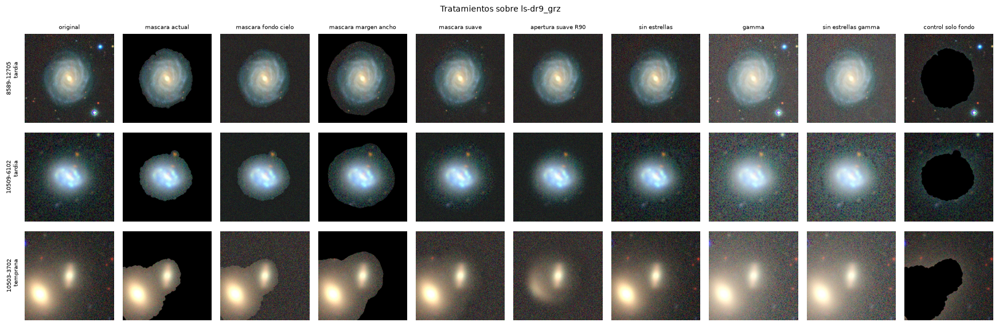

In [18]:
from src.config import MORFOLOGIA_LABEL_TO_INT, RANDOM_SEED, TREATMENT_CV_SEEDS, TREATMENT_VARIANTS
from src.data.image_quality import build_variant_feature_table
from src.data.image_treatments import IMAGE_TREATMENTS
from src.evaluate import multi_seed_paired_comparison
from src.models.linear_probe import build_backbone, embed_images, make_logistic_probe
from src.utils import set_seed

set_seed()
TREATMENT_ORDER = ["original", *IMAGE_TREATMENTS]
treatment_labels = (pd.read_csv(CUTOUTS_INDEX_CSV).drop_duplicates("name")
                    .set_index("name")["label"].sort_index())

# Galería: la galaxia de referencia, una temprana y una tardía, en la primera variante finalista.
gallery_layer, gallery_bands = TREATMENT_VARIANTS[0]
gallery_names = [REFERENCE_NAME, *(treatment_labels[treatment_labels == label].index[0]
                                   for label in sorted(MORFOLOGIA_LABEL_TO_INT))]
rng = np.random.default_rng(RANDOM_SEED)
fig, axes = plt.subplots(len(gallery_names), len(TREATMENT_ORDER),
                         figsize=(1.75 * len(TREATMENT_ORDER), 1.95 * len(gallery_names)))
for row, name in enumerate(gallery_names):
    image = load_jpg_cutout(name, gallery_layer, gallery_bands)
    for col, treatment in enumerate(TREATMENT_ORDER):
        shown = image if treatment == "original" else IMAGE_TREATMENTS[treatment](image, rng)
        axes[row, col].imshow(shown)
        axes[row, col].axis("off")
        if row == 0:
            axes[row, col].set_title(treatment.replace("_", " "), fontsize=7)
    axes[row, 0].text(-0.06, 0.5, f"{name.replace('manga-', '')}\n{treatment_labels[name]}",
                      transform=axes[row, 0].transAxes, rotation=90, va="center", ha="right", fontsize=7)
fig.suptitle(f"Tratamientos sobre {variant_name(gallery_layer, gallery_bands)}", fontsize=10)
plt.tight_layout()
plt.show()

**Qué mirar.** Que cada tratamiento haga lo que dice su nombre. `sin_estrellas` solo borra las
fuentes separadas de la galaxia. Las máscaras suaves y la apertura difuminan hacia un cielo con
ruido, no hacia negro. `gamma` aclara el halo sin saturar el núcleo. `control_solo_fondo` deja ver
la luz de la galaxia que se extiende más allá de la máscara.

In [19]:
# ~1-2 min por variante en CPU: la ResNet se evalúa una vez por tratamiento y variante.
backbone = build_backbone()
treatment_names = list(treatment_labels.index)
y_treat = treatment_labels.map(MORFOLOGIA_LABEL_TO_INT).to_numpy()

treatment_rows = []
for layer, bands in TREATMENT_VARIANTS:
    rng = np.random.default_rng(RANDOM_SEED)
    originals = [load_jpg_cutout(name, layer, bands) for name in treatment_names]
    representations = {"original": embed_images(originals, backbone)}
    for treatment, function in IMAGE_TREATMENTS.items():
        representations[treatment] = embed_images([function(im, rng) for im in originals], backbone)
    for row in multi_seed_paired_comparison(make_logistic_probe(), representations, y_treat,
                                            "original", TREATMENT_CV_SEEDS):
        treatment_rows.append({"variante": variant_name(layer, bands), **row})

treatments = pd.DataFrame(treatment_rows)
treatment_variants = list(dict.fromkeys(treatments["variante"]))
display(treatments.set_index(["variante", "representacion"]).round(3))

auc_media  auc_std_semillas  dif_auc  \
variante        representacion                                               
ls-dr9_grz      original                  0.979             0.010      NaN   
                mascara_actual            0.831             0.028   -0.152   
                mascara_fondo_cielo       0.883             0.024   -0.086   
                mascara_margen_ancho      0.909             0.020   -0.067   
                mascara_suave             0.886             0.020   -0.088   
                apertura_suave_R90        0.923             0.014   -0.061   
                sin_estrellas             0.945             0.013   -0.037   
                gamma                     0.969             0.009   -0.013   
                sin_estrellas_gamma       0.939             0.012   -0.040   
                control_solo_fondo        0.832             0.034   -0.136   
ls-dr10-grz_grz original                  0.973             0.013      NaN   
                mascara_actual            0.842             0.025   -0.139   
                mascara_fondo_cielo       0.880             0.024   -0.078   
                mascara_margen_ancho      0.913             0.025   -0.061   
                mascara_suave             0.889             0.016   -0.085   
                apertura_suave_R90        0.919             0.013   -0.050   
                sin_estrellas             0.931             0.017   -0.045   
                gamma                     0.960             0.010   -0.014   
                sin_estrellas_gamma       0.918             0.016   -0.053   
                control_solo_fondo        0.828             0.031   -0.130   
ls-dr11_grz     original                  0.961             0.017      NaN   
                mascara_actual            0.858             0.025   -0.101   
                mascara_fondo_cielo       0.889             0.022   -0.067   
                mascara_margen_ancho      0.915             0.024   -0.046   
                mascara_suave             0.881             0.021   -0.077   
                apertura_suave_R90        0.914             0.013   -0.043   
                sin_estrellas             0.950             0.015   -0.013   
                gamma                     0.954             0.016   -0.010   
                sin_estrellas_gamma       0.958             0.011   -0.003   
                control_solo_fondo        0.835             0.032   -0.122   
ls-dr11_griz    original                  0.960             0.015      NaN   
                mascara_actual            0.855             0.029   -0.112   
                mascara_fondo_cielo       0.848             0.038   -0.102   
                mascara_margen_ancho      0.893             0.024   -0.070   
                mascara_suave             0.862             0.024   -0.091   
                apertura_suave_R90        0.912             0.017   -0.051   
                sin_estrellas             0.944             0.021   -0.021   
                gamma                     0.945             0.017   -0.021   
                sin_estrellas_gamma       0.941             0.019   -0.021   
                control_solo_fondo        0.693             0.030   -0.262   

                                      ic_inf  ic_sup  p_valor  semillas_mejor  
variante        representacion                                                 
ls-dr9_grz      original                 NaN     NaN      NaN             NaN  
                mascara_actual        -0.277  -0.053    0.000             0.0  
                mascara_fondo_cielo   -0.173  -0.024    0.001             0.0  
                mascara_margen_ancho  -0.146  -0.007    0.027             0.0  
                mascara_suave         -0.180  -0.018    0.001             0.0  
                apertura_suave_R90    -0.128  -0.015    0.002             0.0  
                sin_estrellas         -0.088  -0.003    0.027             0.0  
                gamma                 -0.

In [20]:
# Resumen: diferencia contra la original por tratamiento (filas) y variante (columnas).
compared = treatments[treatments["representacion"] != "original"]
significant = compared.assign(sig=compared["p_valor"] < 0.05)
summary_table = pd.DataFrame({
    "dif_auc_min": compared.groupby("representacion")["dif_auc"].min(),
    "dif_auc_max": compared.groupby("representacion")["dif_auc"].max(),
    "variantes_peor_signif": significant[significant["sig"] & (significant["dif_auc"] < 0)]
        .groupby("representacion").size(),
    "variantes_mejor_signif": significant[significant["sig"] & (significant["dif_auc"] > 0)]
        .groupby("representacion").size(),
    "semillas_mejor_total": compared.groupby("representacion")["semillas_mejor"].sum(),
}).reindex(TREATMENT_ORDER[1:]).fillna(0)
summary_table["semillas_mejor_total"] = (summary_table["semillas_mejor_total"].astype(int).astype(str)
                                         + f" / {len(TREATMENT_CV_SEEDS) * len(treatment_variants)}")
summary_table[["variantes_peor_signif", "variantes_mejor_signif"]] = (
    summary_table[["variantes_peor_signif", "variantes_mejor_signif"]].astype(int))
display(summary_table.round(3))
print("AUC de la original por variante:",
      treatments[treatments["representacion"] == "original"].set_index("variante")["auc_media"].round(3).to_dict())

,dif_auc_min,dif_auc_max,variantes_peor_signif,variantes_mejor_signif,semillas_mejor_total
representacion,,,,,
mascara_actual,-0.152,-0.101,4,0,0 / 40
mascara_fondo_cielo,-0.102,-0.067,4,0,0 / 40
mascara_margen_ancho,-0.070,-0.046,3,0,0 / 40
mascara_suave,-0.091,-0.077,4,0,0 / 40
apertura_suave_R90,-0.061,-0.043,4,0,0 / 40
sin_estrellas,-0.045,-0.013,2,0,5 / 40
gamma,-0.021,-0.010,0,0,6 / 40
sin_estrellas_gamma,-0.053,-0.003,1,0,6 / 40
control_solo_fondo,-0.262,-0.122,4,0,0 / 40


AUC de la original por variante: {'ls-dr9_grz': 0.979, 'ls-dr10-grz_grz': 0.973, 'ls-dr11_grz': 0.961, 'ls-dr11_griz': 0.96}


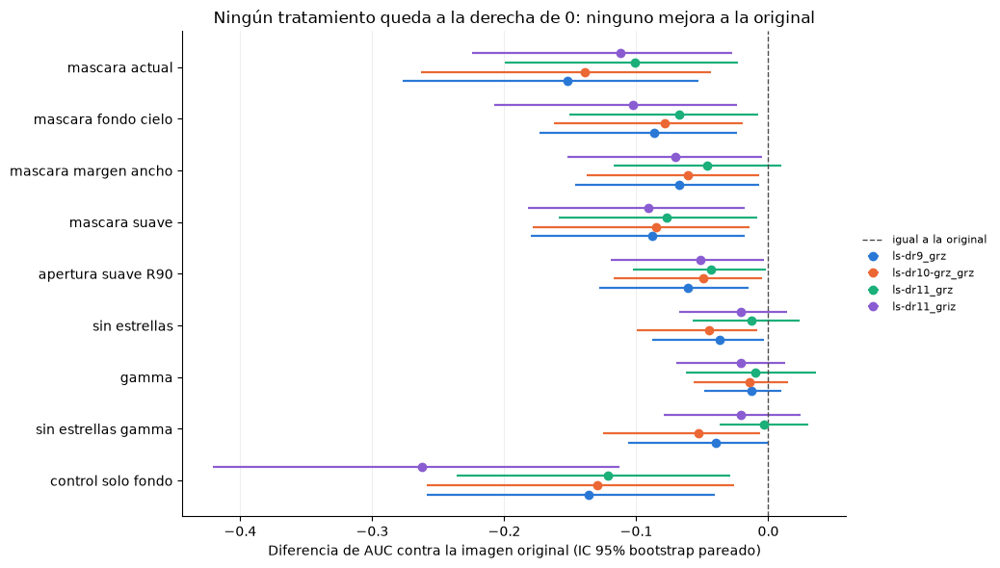

In [21]:
fig, ax = plt.subplots(figsize=(10.5, 6))
treatment_axis = TREATMENT_ORDER[1:]
ypos = np.arange(len(treatment_axis))[::-1]
VARIANT_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#8a5cd1"]  # paleta categórica, slots 1-4
offsets = np.linspace(-0.27, 0.27, len(treatment_variants))
for offset, color, variant in zip(offsets, VARIANT_COLORS, treatment_variants):
    part = compared[compared["variante"] == variant].set_index("representacion").loc[treatment_axis]
    ax.errorbar(part["dif_auc"], ypos + offset,
                xerr=[part["dif_auc"] - part["ic_inf"], part["ic_sup"] - part["dif_auc"]],
                fmt="o", markersize=6, color=color, ecolor=color, elinewidth=1.6, capsize=0, label=variant)
ax.axvline(0, color="0.3", linewidth=1, linestyle="--", label="igual a la original")
ax.set_yticks(ypos, [t.replace("_", " ") for t in treatment_axis])
ax.set_xlabel("Diferencia de AUC contra la imagen original (IC 95% bootstrap pareado)")
ax.grid(axis="x", alpha=0.25, linewidth=0.6)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=8)
ax.set_title("Ningún tratamiento queda a la derecha de 0: ninguno mejora a la original")
plt.tight_layout()
plt.show()

**Lectura de la figura.** Cada renglón es un tratamiento y cada color una variante. El punto es
cuánto cambia el AUC respecto a la imagen original de esa variante, y la línea su IC 95%. A la
izquierda de la línea punteada = peor que la original. Si la línea no la cruza, la pérdida es
significativa.

### Observaciones (muestra de 50, 2026-10-27)

**Ningún tratamiento mejora a la imagen original.** De las 32 comparaciones (8 tratamientos × 4
variantes), ninguna tiene `dif_auc` positiva y ninguna es significativamente mejor. Sumando las 4
variantes, ningún tratamiento supera a la original en más de 6 de las 40 particiones. La mayoría la
empeora de forma significativa; los más leves empatan.

- **La máscara actual (fondo negro) es el peor tratamiento:** −0.10 a −0.15 de AUC, significativa
  en las 4 variantes (p ≤ 0.011). Confirma, ahora contra la original de **cada** variante, lo que
  encontró `notebook/variant-classification-for-images-only.ipynb`. Allí la comparación era contra
  la variante de referencia.
- **Corregir la máscara reduce la pérdida, pero no la elimina.** Fondo de cielo: −0.07 a −0.10.
  Borde suave: −0.08 a −0.09. Margen ancho: −0.05 a −0.07. Apertura R90: −0.04 a −0.06. Todas son
  significativamente peores en las 4 variantes, salvo `mascara_margen_ancho` en `ls-dr11_grz`
  (p = 0.12). Cuanta más imagen se conserva, menos se pierde.
- **Quitar solo las estrellas** pierde −0.01 a −0.05. Es significativo en `ls-dr9_grz` y
  `ls-dr10-grz_grz` (p ≤ 0.03) y empata en las dos DR11.
- **El realce `gamma` no aporta:** −0.01 a −0.02, empate en las 4 variantes (p ≥ 0.27).
  `sin_estrellas_gamma` pierde −0.003 a −0.053 y es significativamente peor solo en
  `ls-dr10-grz_grz`.
- **El control `control_solo_fondo` explica la pérdida.** Con la galaxia en negro, el AUC todavía es
  0.69–0.84. Fuera de la máscara queda información útil para el clasificador: la luz débil del disco
  y del halo que la máscara corta (en la galería se ve el halo alrededor del hueco) y el entorno
  (vecinas). Cualquier recorte tira parte de esa información.
- **En la galería se ve la limitación ya conocida de la máscara** (`manga-10503-3702`): una vecina
  superpuesta queda dentro de la máscara. La apertura R90 sí la separa, pero también pierde
  rendimiento.

**Decisión:** entrenar con la imagen original, sin tratamiento. La máscara con fondo negro no debe
usarse como entrada del modelo; se conserva solo para medir (fracción de la máscara, forma, color).
Si el IA-UNAM pide que la entrada contenga solo la galaxia central, la opción menos costosa es
`sin_estrellas`: pierde ≤ 0.05 y empata en DR11.

**Alcance y preguntas abiertas:**

- Son 50 galaxias y un backbone de ImageNet **congelado**. Con fine-tuning la red podría aprender a
  ignorar estrellas y fondo, y la brecha cambiar. Repetir esta sección con ~2,000 galaxias y con el
  modelo final.
- Parte de lo que el modelo usa fuera de la galaxia es el entorno, y por la relación
  morfología–densidad el entorno sí predice temprana/tardía. Pregunta para el IA-UNAM: ¿el modelo
  debe clasificar solo la galaxia, o puede apoyarse en su entorno?
